<a href="https://colab.research.google.com/github/teju917/Machine_learning_lab2/blob/main/Program_10_%E2%80%93_Explainable_AI_(SHAP_and_LIME).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ORIGINAL DATASET
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4        

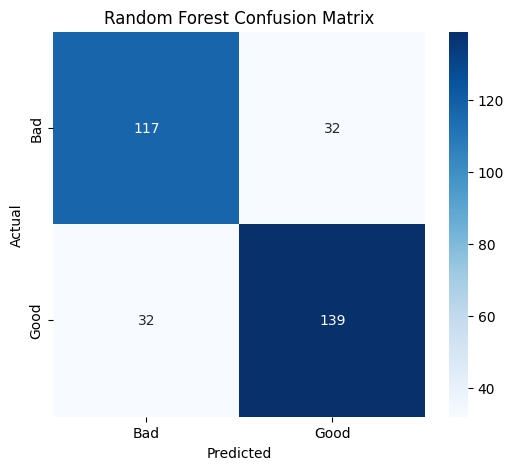


FEATURE IMPORTANCE
                 Feature  Importance
10               alcohol    0.183663
9              sulphates    0.135461
1       volatile acidity    0.112159
6   total sulfur dioxide    0.101122
7                density    0.088501
4              chlorides    0.071348
0          fixed acidity    0.067614
2            citric acid    0.064646
8                     pH    0.063039
5    free sulfur dioxide    0.057834
3         residual sugar    0.054613


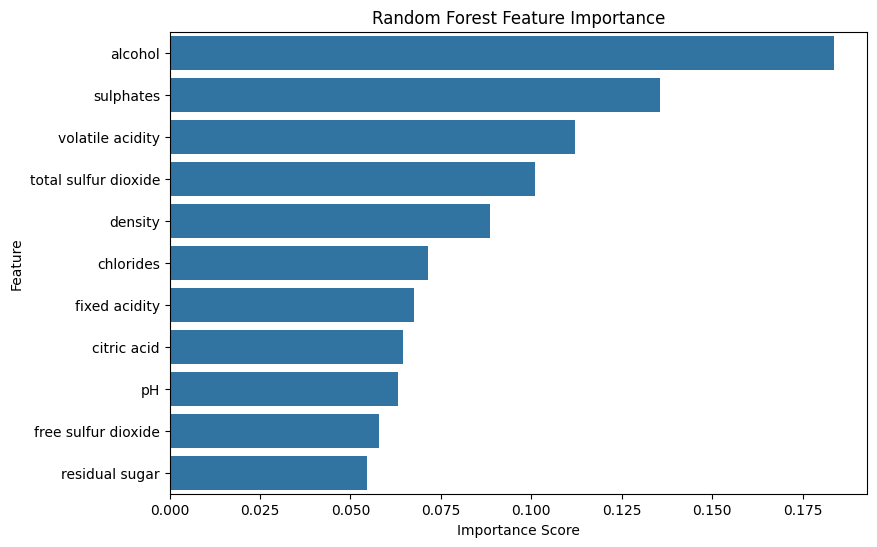


PREDICTIONS FOR TWO TEST INSTANCES

TEST INSTANCE 1
Actual Class: Good
Predicted Class: Bad
Good Quality Probability: 0.385

TEST INSTANCE 2
Actual Class: Bad
Predicted Class: Good
Good Quality Probability: 0.525

SHAP FEATURE IMPORTANCE FOR TWO INSTANCES

TEST INSTANCE 1
             Feature  SHAP Value
             alcohol   -0.068095
    volatile acidity   -0.042453
             density   -0.035747
           chlorides    0.027043
           sulphates    0.023833
         citric acid   -0.014228
       fixed acidity   -0.009000
total sulfur dioxide    0.005082
                  pH   -0.004699
 free sulfur dioxide    0.002880
      residual sugar   -0.000233


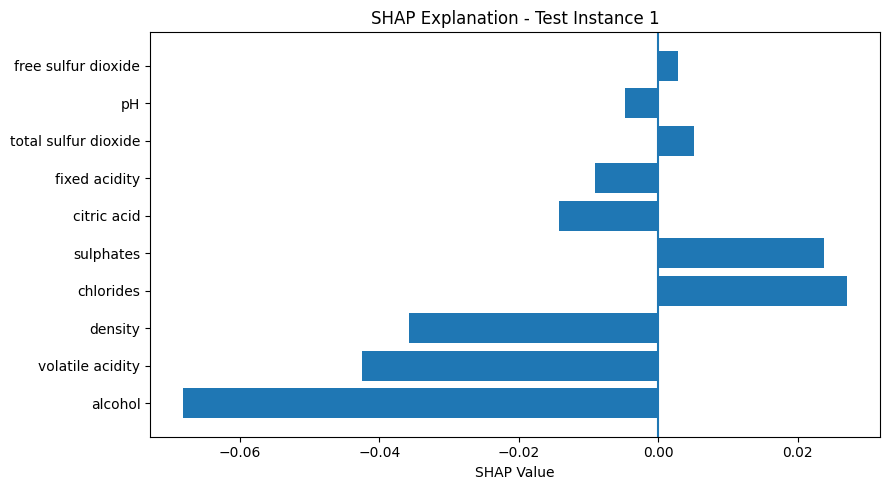


TEST INSTANCE 2
             Feature  SHAP Value
             alcohol    0.090674
    volatile acidity   -0.062581
 free sulfur dioxide   -0.053254
total sulfur dioxide    0.042417
         citric acid   -0.017592
      residual sugar    0.016871
           chlorides    0.013392
       fixed acidity    0.006685
                  pH   -0.005650
           sulphates   -0.004091
             density   -0.002488


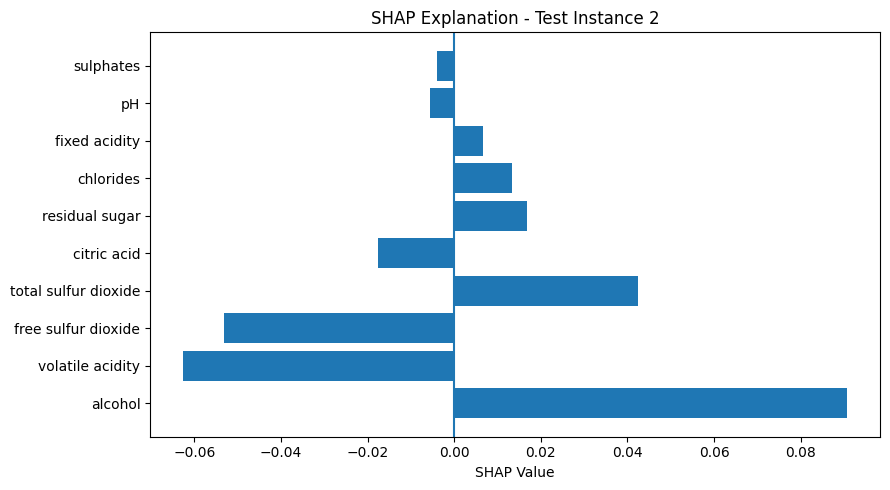

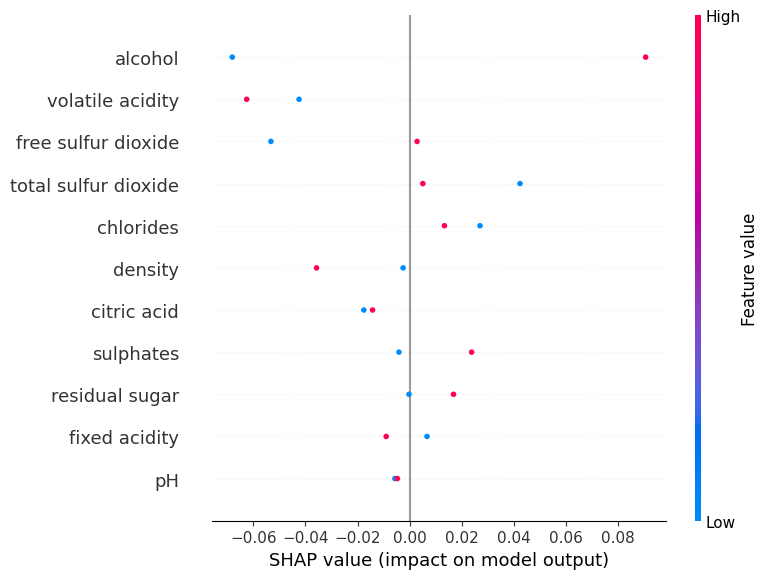


LIME EXPLANATIONS

TEST INSTANCE 1
Actual Class: Good
Predicted Class: Bad

LIME FEATURE CONTRIBUTIONS
9.50 < alcohol <= 10.20 : -0.1147
1.00 < density <= 1.00 : -0.0366
0.52 < volatile acidity <= 0.64 : -0.0299
0.26 < citric acid <= 0.43 : 0.0135
38.00 < total sulfur dioxide <= 61.00 : 0.0115
1.90 < residual sugar <= 2.20 : -0.0074
8.00 < free sulfur dioxide <= 14.00 : 0.0062
0.08 < chlorides <= 0.09 : 0.0033
0.55 < sulphates <= 0.62 : 0.0021
7.90 < fixed acidity <= 9.30 : 0.0012


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


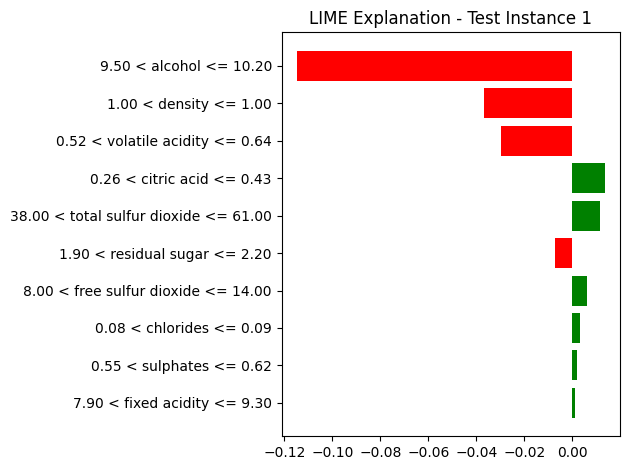

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(



TEST INSTANCE 2
Actual Class: Bad
Predicted Class: Good

LIME FEATURE CONTRIBUTIONS
volatile acidity > 0.64 : -0.0919
10.20 < alcohol <= 11.10 : 0.0606
22.00 < total sulfur dioxide <= 38.00 : 0.0557
chlorides > 0.09 : -0.0379
1.00 < density <= 1.00 : -0.0197
free sulfur dioxide <= 8.00 : -0.0133
0.55 < sulphates <= 0.62 : -0.007
3.31 < pH <= 3.40 : 0.0056
2.20 < residual sugar <= 2.60 : 0.002
7.90 < fixed acidity <= 9.30 : 0.0019


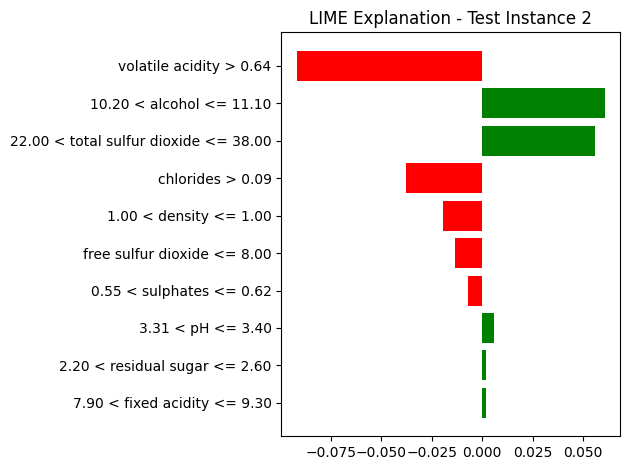


FINAL RESULT
Random Forest model trained successfully.
SHAP explanations generated successfully.
LIME explanations generated successfully.
Feature importance analyzed for two test instances.
Explainable AI implementation completed.


In [1]:
# INSTALL LIBRARIES
!pip install shap lime scikit-learn pandas numpy matplotlib seaborn -q

# IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from lime.lime_tabular import LimeTabularExplainer

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. READ DATASET FROM URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("ORIGINAL DATASET")
print(df.head())

print("\nDATASET INFORMATION")
print("Total examples:", len(df))
print("Number of columns:", len(df.columns))

print("\nQUALITY DISTRIBUTION")
print(df["quality"].value_counts().sort_index())

# 2. DATA PREPROCESSING
df["quality"] = df["quality"].apply(
    lambda x: 1 if x >= 6 else 0
)

X = df.drop("quality", axis=1)
y = df["quality"]

X = X.fillna(X.median())

# 3. SPLIT DATASET
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTRAINING EXAMPLES:", len(X_train))
print("TESTING EXAMPLES:", len(X_test))

# 4. TRAIN RANDOM FOREST MODEL
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("\nMODEL TRAINED SUCCESSFULLY")

# 5. PREDICTIONS
y_prediction = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_prediction
)

print("\nMODEL ACCURACY:", round(accuracy, 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_prediction,
        target_names=["Bad Quality", "Good Quality"],
        zero_division=0
    )
)

# 6. CONFUSION MATRIX
cm = confusion_matrix(y_test, y_prediction)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Bad", "Good"],
    yticklabels=["Bad", "Good"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

# 7. GLOBAL FEATURE IMPORTANCE
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE")
print(importance)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")

plt.show()

# 8. SELECT TWO TEST INSTANCES
X_two = X_test.iloc[:2].copy()

y_two = y_test.iloc[:2]

predictions = model.predict(X_two)

probabilities = model.predict_proba(X_two)

print("\nPREDICTIONS FOR TWO TEST INSTANCES")

for i in range(2):

    print("\nTEST INSTANCE", i + 1)

    print("Actual Class:",
          "Good" if y_two.iloc[i] == 1 else "Bad")

    print("Predicted Class:",
          "Good" if predictions[i] == 1 else "Bad")

    print("Good Quality Probability:",
          round(probabilities[i][1], 4))

# 9. SHAP EXPLANATION
explainer = shap.TreeExplainer(model)

shap_explanation = explainer(X_two)

shap_values = np.asarray(shap_explanation.values)

# Select SHAP values for the Good Quality class
if shap_values.ndim == 3:
    shap_good = shap_values[:, :, 1]
else:
    shap_good = shap_values

print("\nSHAP FEATURE IMPORTANCE FOR TWO INSTANCES")

for i in range(2):

    shap_importance = pd.DataFrame({
        "Feature": X.columns,
        "SHAP Value": shap_good[i],
        "Absolute Importance": np.abs(shap_good[i])
    })

    shap_importance = shap_importance.sort_values(
        by="Absolute Importance",
        ascending=False
    )

    print("\nTEST INSTANCE", i + 1)

    print(
        shap_importance[
            ["Feature", "SHAP Value"]
        ].to_string(index=False)
    )

    top_features = shap_importance.head(10)

    plt.figure(figsize=(9, 5))

    plt.barh(
        top_features["Feature"],
        top_features["SHAP Value"]
    )

    plt.axvline(0)

    plt.xlabel("SHAP Value")
    plt.title("SHAP Explanation - Test Instance " + str(i + 1))

    plt.tight_layout()
    plt.show()

# 10. SHAP SUMMARY PLOT
shap.summary_plot(
    shap_good,
    X_two,
    feature_names=list(X.columns),
    show=True
)

# 11. LIME EXPLANATION
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X.columns),
    class_names=["Bad Quality", "Good Quality"],
    mode="classification",
    random_state=42
)

print("\nLIME EXPLANATIONS")

for i in range(2):

    explanation = lime_explainer.explain_instance(
        X_two.iloc[i].values,
        model.predict_proba,
        num_features=10,
        labels=(1,)
    )

    print("\nTEST INSTANCE", i + 1)

    print("Actual Class:",
          "Good" if y_two.iloc[i] == 1 else "Bad")

    print("Predicted Class:",
          "Good" if predictions[i] == 1 else "Bad")

    print("\nLIME FEATURE CONTRIBUTIONS")

    for feature, value in explanation.as_list(label=1):
        print(feature, ":", round(value, 4))

    fig = explanation.as_pyplot_figure(label=1)

    plt.title("LIME Explanation - Test Instance " + str(i + 1))

    plt.tight_layout()
    plt.show()

# 12. FINAL RESULT
print("\n" + "=" * 60)
print("FINAL RESULT")
print("=" * 60)

print("Random Forest model trained successfully.")
print("SHAP explanations generated successfully.")
print("LIME explanations generated successfully.")
print("Feature importance analyzed for two test instances.")
print("Explainable AI implementation completed.")